In [1]:
from os.path import join, dirname
import os
import sys
import gc
import logging
import argparse
from copy import deepcopy
import numpy as np
import torchshow as ts
import torchvision
from einops import rearrange, repeat
from matplotlib import pyplot as plt

import torch
from torch import autocast
from torch.cuda.amp import GradScaler
import torch.nn.functional as F
import torch.distributed as dist
import torch.multiprocessing as mp
from torch.autograd import grad, Variable

sys.path.append(join(dirname(dirname(os.getcwd()))))
sys.path.append(os.getcwd())

from memoryPerceiver.memory_perceiver.main.configuration import cf
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_memories, reset_memories
from memoryPerceiver.memory_perceiver.core.distributed import setup_distributed, average_gradients, scatter_dummy_src, gather_dummy_src
from memoryPerceiver.memory_perceiver.core.miscellaneous import custom_random, print_cuda_tensors
import memoryPerceiver.memory_perceiver.isaac.trainer as tr
from memoryPerceiver.memory_perceiver.isaac.plot import Plotter
from memoryPerceiver.memory_perceiver.isaac.agent import ActorCritic, ActorCriticSimple, ActorCriticPerceiver, create_agent

from memoryPerceiver.memory_perceiver.core.model_net import PerceiverIO
from memoryPerceiver.memory_perceiver.core.model_wrapper import create_multimodal_perceiver, output_projection, input_embedding
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.rnn import SimpleRNN
from memoryPerceiver.memory_perceiver.core.rtrl import UORO, RTRL, RTRL_partial

%load_ext autoreload
%autoreload 2
device = 'cuda:1'

In [2]:
import numpy as np


def one_hot_encode(value, n_class):
    vec = np.zeros([n_class])
    vec[value] = 1
    return vec


def one_hot_decode(encoded_seq):
    return [np.argmax(vector) for vector in encoded_seq]


def get_an_bn_array(num_data, k, l):
    """
    modified from https://github.com/petered/uoro-demo
    """
    x = np.zeros([num_data], dtype=int)

    i = 0
    while i < num_data:
        n = np.random.randint(low=k, high=l+1)
        x[i:i+n] = 1
        x[i+n+1: i+2*n+1] = 2
        i += 2*n + 2
    return x


def generate_anbn_data(num_data, k=1, l=4, num_class=3):
    X_arr = get_an_bn_array(num_data+1, k, l)
    X = np.zeros([1, num_data, num_class])
    Y = np.zeros([1, num_data, num_class])
    for i in range(num_data):
        X[0, i] = one_hot_encode(X_arr[i], num_class)
        Y[0, i] = one_hot_encode(X_arr[i+1], num_class)
    return X, Y


X, Y = generate_anbn_data(10000, k=10, l=20, num_class=3)
X = torch.from_numpy(X).float().to(device)
Y = torch.from_numpy(np.argmax(Y, axis=2)).long().to(device)

In [101]:
# RNN
loss_all=[]
l = []
loss_acc=0
input_size=3
hidden_size=10
output_size=3
old_s = torch.zeros(size=[1, 1, hidden_size], requires_grad=True, device=device)
criterion=torch.nn.CrossEntropyLoss()
model=SimpleRNN(3,hidden_size,3).to(device)
uoro_grad = UORO(model)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
# UORO
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss=criterion(y[0], y_t)
        uoro_grad.step(model, x_t, new_s, old_s, loss)
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

In [ ]:
# BPTT
loss=torch.tensor(0.0, device=device)
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)

        y, new_s = model(x_t, old_s)
        loss+=criterion(y.squeeze(0), y_t)
        # uoro_grad.step(model, x_t, new_s, old_s, loss)
        if iter_id % 5 == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/5)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%100 == 0:
            print(loss_acc)
            loss_acc=0

In [3]:
from google.cloud import bigquery
from google.oauth2 import service_account

credentials = service_account.Credentials.from_service_account_file('/isaac-sim/memoryPerceiver/service_account.json')
client = bigquery.Client(credentials=credentials)
table = client.get_table(f"{credentials.project_id}.influence.test")
# client.insert_rows_from_dataframe(table, df, chunk_size=500)
# job = client.load_table_from_dataframe(df, table)
# job.result()
# params = ', '.join(str(x) for x in name_list)
# h_indexes = ', '.join(str(hi.item()) for hi in slice_indexes_t)
# query = f"""
#     SELECT h_i, param, p_j, dh_dtheta
#     FROM `{credentials.project_id}.influence.test`
#     WHERE h_i IN (1,2) ;
#     """
# rs = client.query(query)

In [44]:
inverse_slice = rtrl_grad.get_inverse_slice()
k_j_k__j=rtrl_grad.get_inverse_j_mappings()
h_i = inverse_slice[df['h_i']]
p_j = k_j_k__j[0, df['p_j']]
rtrl_grad.d_state_d_theta[h_i, p_j] = torch.tensor(df['dh_dtheta'] ,device=device)

In [35]:
# pip install db-dtypes parrow google-cloud-bigquery-storage
rtrl_grad.table_save = 'test'
rtrl_grad.save_influence()
rtrl_grad.d_state_d_theta.count_nonzero()
rtrl_grad.load_influence()

In [32]:
import pandas as pd 
j__k, j__j_k = map(lambda x: torch.tensor(x, device=device), rtrl_grad.get_j_mappings())
valid_mask = ~rtrl_grad.d_state_d_theta.isnan() & (rtrl_grad.d_state_d_theta != 0)
valid_indices = valid_mask.nonzero()
slice_indexes_t = torch.tensor(rtrl_grad.slice_indexes, device=device)
name_list = np.array([hash(s) for s in rtrl_grad.nn_param_state.name_list])
df = pd.DataFrame( {"h_i": slice_indexes_t[valid_indices[:, 0]].cpu().numpy(),
                    "param": name_list[j__k[valid_indices[:, 1]].cpu().numpy()],
                    "p_j": j__j_k[valid_indices[:, 1]].cpu().numpy(),
                    "dh_dtheta": rtrl_grad.d_state_d_theta[valid_indices[:, 0], valid_indices[:, 1]].cpu().numpy()} )

In [30]:
# Mem Perceiver
from memoryPerceiver.memory_perceiver.main.configuration import cf
loss_all = []
loss_acc=0
criterion=torch.nn.CrossEntropyLoss()
cf.body_outputs['critic']=3 # agent.py -> values = rearrange(output['critic'], 'b () d -> b d')
cf.shared=True 
cf.dim_observations=3
cf.num_envs=1
cf.depth=1
cf.query_dim=512 # 8 512
cf.nb_latents=2
cf.nb_latents_mem=1024 # 4 1024
cf.latent_dim_head=2
model=create_agent(cf, device)
old_s = create_memories(model.actor, cf.num_envs, device=device)
mem_dim = old_s.shape
model.flattened_mem = mem_dim
old_s = rearrange(old_s, 'b l h -> (b l h)')
# for name, p in model.named_parameters():
#     if name.startswith('actor.state_'):
#         if name.startswith('actor.state_cross_attn.fn'):
#             p.requires_grad = True
#         else:
#             p.requires_grad = False
rtrl_grad = RTRL_partial(model, param_state_filter='actor.state_', num_parameters=1,
                         chunk_size=128, slice_indexes=list(range(524288-4096, 524288)) ) # (16, 32), (524288-4096, 524288)
# rtrl_grad = RTRL(model)
# uoro_grad = UORO(model, epsilon_perturbation=1e-7)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model.train()
dummy0=torch.zeros(cf.num_envs, 1, cf.dim_actions, device=device)
states = {}

In [ ]:
from torch.func import vmap, jacrev, jacfwd, functional_call
from torch.autograd import grad

# params = {}
# for name, p in model.named_parameters():
#     if p.requires_grad and not name.startswith('actor.state_'):
#         params[name]=p.detach()
params = dict(model.named_parameters())
key='actor.out_cross_ff.net.0.weight'
params = {key: params[key]}
slice_indexes = list(range(524288-65536, 524288))
old_s_sliced = old_s[slice_indexes].detach()
x_t = X[:, 0:(0+1)].reshape([1, 1, 3]).to(device)
states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)

def fmodel(params, old_s_sliced): #functional version of model
    # with torch.no_grad():
    old_s_clone = old_s.clone()
    old_s_clone[slice_indexes] = old_s_sliced
    _, _, _, new_s = functional_call(model, params, (states, old_s_clone), {'old_actions':dummy0})
    return new_s[:256]


# result = vmap(jacrev(fmodel, argnums=(0)), in_dims=(None,0))(params, old_s)
%time new_s = fmodel(params, old_s_sliced)
_, y, _, new_s = model(states, old_s, old_actions=dummy0)


# %time jac0=[grad(outputs=o, inputs=param_list, allow_unused=True, retain_graph=True)for o in new_s]
# %time jac=jacrev(fmodel, argnums=(1))(params, old_s)
# with torch.no_grad():
def compute_jac(argnum):
    jac=jacrev(fmodel, argnums=(argnum))(params, old_s_sliced)
    return jac
jac = compute_jac(1)
jac = compute_jac(0)
# jac=jac.detach()
# new_s = new_s.detach()
#%time jac=jacfwd(fmodel, argnums=(1))(params, old_s)
# %time jac = vmap(jacrev(fmodel, argnums=(0)), in_dims=(None,0))(params, old_s)
# for k, j in jac.items():
#     if torch.count_nonzero(j)>0 :
#         print(k,j.shape)

In [9]:
# print(rtrl_grad.d_state_d_theta.size())
print(rtrl_grad.d_state_d_theta.count_nonzero() / (rtrl_grad.d_state_d_theta.shape[0] * rtrl_grad.d_state_d_theta.shape[1]))
#torch.sparse.check_sparse_tensor_invariants.enable()
# rtrl_grad.slice_indexes=list(range(0,32))
# rtrl_grad = RTRL_partial(model, param_state_filter='actor.state_', num_parameters=260,
#                          chunks=1, slice_indexes=list(range(0,16)) )
torch.cuda.empty_cache() 
# for param_group in optimizer.param_groups:
#     param_group['lr'] = 1e-4
print(rtrl_grad.chunk_size)
print(len(rtrl_grad.slice_indexes))

tensor(0.1250, device='cuda:1')
128
4096


In [31]:
# RTRL
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:   , iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)
        _, y, _, new_s = model(states, old_s, old_actions=dummy0)
        # y = torch.nn.functional.softmax(y)
        loss=criterion(y, y_t)
        rtrl_grad.step_safe(model, states, old_s, loss, old_actions=dummy0)
        # loss.backward()
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1 == 0:
            print(loss_acc)
            loss_acc=0

0.9225709438323975


KeyboardInterrupt: 

In [5]:
# BPTT
loss=torch.tensor(0.0, device=device)
horizon=10
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:, iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)

        _, y, _, new_s = model(states, old_s, old_actions=dummy0)
        loss+=criterion(y, y_t)
        if iter_id % horizon == 0:
            optimizer.zero_grad()
            loss.backward()
            old_s = new_s.detach().clone().requires_grad_(True)
            optimizer.step()
            loss_all.append(loss.item()/horizon)
            loss_acc += loss.item()
            loss=torch.tensor(0.0, device=device)
        else:
            old_s = new_s.clone() #.detach().clone()  #.detach().clone().requires_grad_(True)
        
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

TypeError: ActorCriticPerceiver.forward() got an unexpected keyword argument 'flattened_mem'

In [ ]:
# UORO
for round in range (100):
    for iter_id in range(10000):
        x_t = X[:, iter_id:(iter_id+1)].reshape([1, 1, 3]).to(device)
        states['observations'] = repeat(x_t, '() t d -> b t d', b=cf.num_envs)
        y_t = Y[:   , iter_id:(iter_id+1)].reshape([1]).to(device)
        y_t = repeat(y_t, '1 -> b', b=cf.num_envs)
        _, y, _, new_s = model(states, old_s, old_actions=dummy0, flattened_mem=mem_dim)
        # y = torch.nn.functional.softmax(y)
        loss=criterion(y, y_t)
        uoro_grad.step(model, states, new_s, old_s, loss, old_actions=dummy0, flattened_mem=mem_dim)
        # loss.backward()
        old_s = new_s.detach().clone().requires_grad_(True)
        optimizer.step()
        optimizer.zero_grad()
        loss_all.append(loss.item())
        loss_acc += loss.item()
        if iter_id%1000 == 0:
            print(loss_acc)
            loss_acc=0

/tmp/ipykernel_1693/1952247719.py:6: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmax' will be ignored
  plt.scatter(x=list(range(0,len(loss_all),h)) , y=[sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.1, vmax=1)


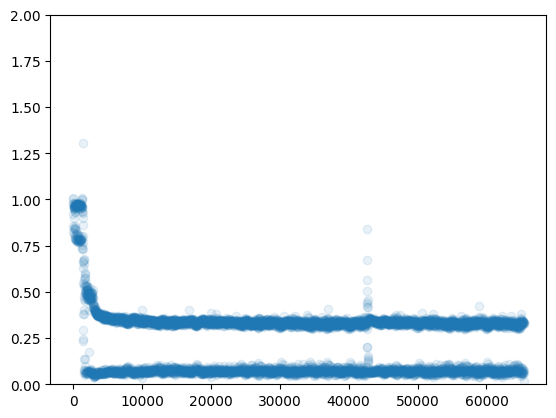

In [93]:
# < 0.68 and close to 0.25 RNN
# plt.plot(loss_all)
# loss_all = [x for x in loss_all if x <2]
h=10
#plt.plot([sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.5)
plt.scatter(x=list(range(0,len(loss_all),h)) , y=[sum(loss_all[i: i+h])/h for i in range(0,len(loss_all),h)], alpha=0.1, vmax=1)
plt.ylim(0, 2)
plt.show()